# Анализ данных в Python. Финальный экзамен

Козлов Андрей, ФИБ'2028

Данные: записи событий матчей плей-офф НХЛ сезона 2025/2026 (`NHL-playoffs-2026.xlsx`).
Для задачи 15 в той же папке должен лежать файл `rink.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from pathlib import Path

from rink import plot_rink

pd.set_option('display.precision', 3)
pd.set_option('display.width', 120)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', font_scale=0.95)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)

def savefig(name):
    """Сохраняет текущий рисунок в PDF (для отчёта) и PNG."""
    plt.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')

## Задача 1. Чтение данных

Первый столбец файла содержит номер строки, поэтому читаем его как индекс (`index_col=0`),
тогда получается 38 столбцов, как в примере.

При просмотре имён обнаружилось, что у трёх игроков кодировка испорчена: UTF-8 был прочитан как Latin-1
(`Juraj SlafkovskÃ½` вместо `Juraj Slafkovský`). Исправляем такие строки обратным преобразованием.
Дату переводим в тип `datetime`.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

AWAY_ON = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Away Team's Goalie"]
HOME_ON = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Home Team's Goalie"]
EVENT_PLAYERS = [f'Player in the Event #{i}' for i in range(1, 4)]
NAME_COLS = EVENT_PLAYERS + AWAY_ON + HOME_ON

def fix_encoding(s):
    """Чинит строки, где UTF-8 был ошибочно декодирован как Latin-1."""
    if isinstance(s, str) and 'Ã' in s:
        try:
            return s.encode('latin-1').decode('utf-8')
        except UnicodeError:
            return s
    return s

broken = sorted({v for c in NAME_COLS for v in events[c].dropna().unique() if 'Ã' in v})
for c in NAME_COLS:
    events[c] = events[c].map(fix_encoding)
events['Date'] = pd.to_datetime(events['Date'])

print(events.shape)
print('Исправлены имена:', {b: fix_encoding(b) for b in broken})

(29710, 38)
Исправлены имена: {'Juraj SlafkovskÃ½': 'Juraj Slafkovský', 'Oskar BÃ¤ck': 'Oskar Bäck', 'Tim StÃ¼tzle': 'Tim Stützle'}


In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


In [4]:
# Внутри каждой игры события упорядочены по Play ID: это понадобится,
# когда будем смотреть на предыдущее событие (задачи 9, 21, 22)
assert events.groupby('Game ID')['Play ID'].apply(lambda s: s.is_monotonic_increasing).all()
print('Игр:', events['Game ID'].nunique(), '| команд:', events['Home Team'].nunique())
events['Play Type'].value_counts()

Игр: 82 | команд: 16


Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

## Задача 2. Сводная таблица по играм

Счёт в поле `Cumulated ... Score` накопленный, поэтому итоговый счёт равен максимуму по игре.
Число овертаймов определяем по номеру последнего периода: 3 означает основное время,
4 означает один овертайм, 5 означает два овертайма.

In [5]:
games = events.groupby('Game ID').agg(**{
    'Date':       ('Date', 'first'),
    'Away Team':  ('Away Team', 'first'),
    'Home Team':  ('Home Team', 'first'),
    'Away Score': ('Cumulated Away Score', 'max'),
    'Home Score': ('Cumulated Home Score', 'max'),
    'Periods':    ('Period', 'max'),
})

def outcome(periods):
    if periods <= 3:
        return 'Final'
    if periods == 4:
        return 'Final/OT'
    return f'Final/{periods - 3}OT'

games['Outcome'] = games['Periods'].map(outcome)
games = games.drop(columns='Periods')
print(games.columns)
games.iloc[-5:, -4:]

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
# Проверка: счёт совпадает с числом событий goal у каждой команды
goal_cnt = (events[events['Play Type'] == 'goal']
            .groupby(['Game ID', 'Team Making the Play']).size())
check_away = [goal_cnt.get((g, t), 0) for g, t in zip(games.index, games['Away Team'])]
check_home = [goal_cnt.get((g, t), 0) for g, t in zip(games.index, games['Home Team'])]
print('Расхождений:', (games['Away Score'] != check_away).sum() + (games['Home Score'] != check_home).sum())
games['Outcome'].value_counts()

Расхождений: 0


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

## Задача 3. Функция gameInfo

Формат как в условии: сначала хозяева, потом гости, счёт в том же порядке.

In [7]:
def gameInfo(gameId):
    """Краткое описание игры: 'Хозяева - Гости (голы хозяев - голы гостей, исход, дата)'."""
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']:%Y-%m-%d})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Для контекста восстановим итоги серий: последние три цифры Game ID означают раунд, номер серии и номер матча.

In [8]:
series = games.assign(
    Round=games.index % 1000 // 100,
    Series=games.index % 100 // 10,
    Winner=np.where(games['Home Score'] > games['Away Score'], games['Home Team'], games['Away Team']))
rows = []
for (rnd, ser), d in series.groupby(['Round', 'Series']):
    wins = d['Winner'].value_counts()
    winner = wins.idxmax()
    loser = (set(d['Home Team']) | set(d['Away Team'])).difference({winner}).pop()
    rows.append({'Round': rnd, 'Series': ser, 'Winner': winner, 'Loser': loser,
                 'Result': f'{wins.max()}-{wins.get(loser, 0)}'})
series_res = pd.DataFrame(rows).set_index(['Round', 'Series'])
series_res

Winner                 Loser Result
Round Series                                                   
1     1             Buffalo Sabres         Boston Bruins    4-2
      2         Montréal Canadiens   Tampa Bay Lightning    4-3
      3        Carolina Hurricanes       Ottawa Senators    4-0
      4        Philadelphia Flyers   Pittsburgh Penguins    4-2
      5         Colorado Avalanche     Los Angeles Kings    4-0
      6             Minnesota Wild          Dallas Stars    4-2
      7       Vegas Golden Knights          Utah Mammoth    4-2
      8              Anaheim Ducks       Edmonton Oilers    4-2
2     1         Montréal Canadiens        Buffalo Sabres    4-3
      2        Carolina Hurricanes   Philadelphia Flyers    4-0
      3         Colorado Avalanche        Minnesota Wild    4-1
      4       Vegas Golden Knights         Anaheim Ducks    4-2
3     1        Carolina Hurricanes    Montréal Canadiens    4-1
      2       Vegas Golden Knights    Colorado Avalanche    4-0
4     1        Carolina Hurricanes  Vegas Golden Knights    4-2

## Задача 4. Число голов в матче

In [9]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

In [10]:
ts = games['Total Score']
print(f'Мода: {ts.mode().tolist()}, дисперсия: {ts.var():.3f}, '
      f'дисперсия/среднее: {ts.var() / ts.mean():.3f}, асимметрия: {ts.skew():.3f}')
ts.value_counts().sort_index()

Мода: [5], дисперсия: 5.106, дисперсия/среднее: 0.861, асимметрия: 0.777


Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

## Задача 5. Гистограмма числа голов

Используем `countplot` с явно заданным порядком значений от минимума до максимума, чтобы
значения, которые не встретились ни разу, тоже были на оси (с нулевой высотой).
Для сравнения точками нанесено ожидаемое число матчей при распределении Пуассона
с тем же средним.

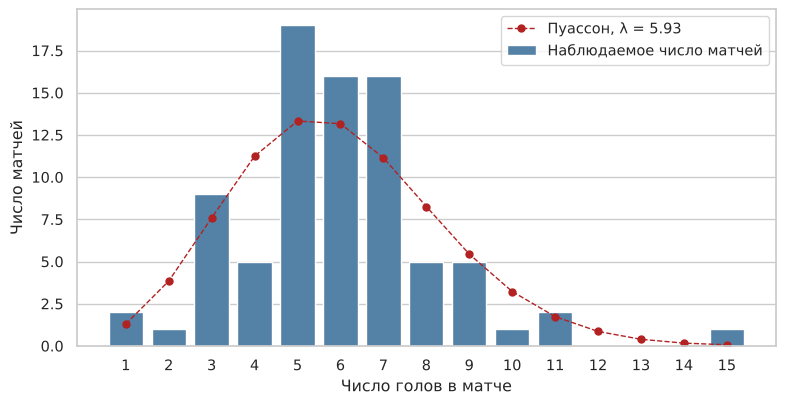

Матчей с 5-7 голами: наблюдается 51, по Пуассону 37.6
Матчей с <=4 или >=8 голами: наблюдается 31, по Пуассону 44.1


In [11]:
order = list(range(ts.min(), ts.max() + 1))
lam = ts.mean()

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.countplot(x=ts, order=order, color='steelblue', ax=ax, label='Наблюдаемое число матчей')
ax.plot(range(len(order)), stats.poisson.pmf(order, lam) * len(ts), 'o--',
        color='firebrick', ms=5, lw=1, label=f'Пуассон, λ = {lam:.2f}')
ax.set_xlabel('Число голов в матче')
ax.set_ylabel('Число матчей')
ax.legend()
plt.tight_layout()
savefig('fig05_total_goals')
plt.show()

expected = pd.Series(stats.poisson.pmf(order, lam) * len(ts), index=order)
observed = ts.value_counts().reindex(order, fill_value=0)
print(f'Матчей с 5-7 голами: наблюдается {observed.loc[5:7].sum()}, по Пуассону {expected.loc[5:7].sum():.1f}')
print(f'Матчей с <=4 или >=8 голами: наблюдается {observed.drop(range(5, 8)).sum()}, '
      f'по Пуассону {expected.drop(range(5, 8)).sum():.1f}')

Вывод: в среднем за матч забивали 5,93 шайбы, медиана 6, мода 5. В половине матчей было от 5 до 7 голов
(51 матч из 82). Распределение слегка скошено вправо (коэффициент асимметрии 0,78) из-за одиночного матча
с 15 голами; без него максимум был бы 11. Дисперсия (5,11) меньше среднего, отношение 0,86. Для числа редких
независимых событий естественно ожидать распределение Пуассона, у которого дисперсия равна среднему.
Здесь матчи сильнее сконцентрированы в центре (5–7 голов: 51 наблюдение против 37,6 по Пуассону),
а «хвосты» беднее. Одна из возможных причин в устройстве плей-офф: овертайм идёт до первой шайбы,
поэтому в нём забивают ровно один гол, а при крупном счёте игра обычно затихает.

## Задача 6. Самые нерезультативные и самые результативные игры

In [12]:
min_games = [gameInfo(i) for i in games.index[ts == ts.min()]]
max_games = [gameInfo(i) for i in games.index[ts == ts.max()]]
print(min_games)
print(max_games)

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


## Задача 7. Число игроков, участвовавших в игре

Переводим 14 столбцов с составами на льду (по 6 игроков и вратарь у каждой команды)
в длинный формат, убираем пропуски и дубликаты и считаем уникальные пары
«команда, игрок» в каждой игре. Вратари уже входят в списки `Player on the Ice`, столбцы
`Goalie` добавлены для надёжности, дубликаты всё равно удаляются.

In [13]:
def roster(cols, side_team):
    long = events[['Game ID', side_team] + cols].melt(id_vars=['Game ID', side_team],
                                                      value_name='Player')
    return long.rename(columns={side_team: 'Team'})[['Game ID', 'Team', 'Player']]

on_ice = (pd.concat([roster(AWAY_ON, 'Away Team'), roster(HOME_ON, 'Home Team')])
            .dropna(subset=['Player'])
            .drop_duplicates()
            .reset_index(drop=True))

goalie_names = set(pd.concat([events["Away Team's Goalie"], events["Home Team's Goalie"]]).dropna())

# Один и тот же игрок не встречается за обе команды в одной игре
assert not on_ice.duplicated(['Game ID', 'Player']).any()

player_count = on_ice.groupby('Game ID').size().rename('Player Count')
top7 = player_count[player_count == player_count.max()]
pd.DataFrame({'Game Info': [gameInfo(i) for i in top7.index], 'Player Count': top7})

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


In [14]:
# Распределение числа игроков по матчам и число вратарей, сыгравших за команду
goalies_used = on_ice[on_ice['Player'].isin(goalie_names)]
n_goalies = goalies_used.groupby('Game ID').size().rename('Goalies')
print(pd.crosstab(player_count, n_goalies))

# Если считать уникальные значения вместе с NaN, получилось бы на единицу больше
g216 = events.loc[events['Game ID'] == 2025030216, AWAY_ON + HOME_ON]
print('С учётом NaN:', len(pd.unique(g216.values.ravel())),
      '| без NaN:', g216.stack().nunique())

Goalies        2  3  4
Player Count          
38            73  0  0
39             0  8  0
40             0  0  1
С учётом NaN: 41 | без NaN: 40


Вывод по задачам 6 и 7: меньше всего голов (по одному) было в двух матчах, оба выиграны 1:0 в овертайме.
Больше всего (15) в матче Colorado Avalanche – Minnesota Wild 9:6.

Максимальное число участников, 40, было в матче Montréal Canadiens – Buffalo Sabres (3:8). В заявке команды НХЛ
20 человек (18 полевых и 2 вратаря), так что 40 означает, что сыграли все заявленные обеими командами, включая
обоих вратарей у каждой. Типичный матч даёт 38 участников (по 18 полевых и одному вратарю), 39 бывает, когда
одну команду меняли вратаря. В примере из условия для этого матча указано 41: столько получится, если посчитать
пропуск `NaN` (составы, где на льду меньше шести человек) за отдельного «игрока».

## Задача 8. Расстояние от точки броска до ворот

Ворота считаем отрезком от $(X,-3)$ до $(X,3)$. Расстояние до отрезка равно
$\sqrt{(x-X)^2 + (y - \mathrm{clip}(y,-3,3))^2}$; это ровно формула из условия:
при $y<-3$ получаем $y+3$, при $y>3$ получаем $y-3$, иначе ноль.

Если хозяева защищают левые ворота, то их броски летят в правые ($X=89$), а броски гостей в левые
($X=-89$); при `right` наоборот. Поэтому $X = 89$ ровно тогда, когда «бросают хозяева» и
«хозяева защищают левые ворота» одновременно истинны или одновременно ложны.

In [15]:
SHOT_TYPES = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(SHOT_TYPES)
is_home = events['Team Making the Play'] == events['Home Team']
home_left = events["Home Team's Defending Side"] == 'left'

# +1, если команда атакует правые ворота, -1, если левые
attack_dir = pd.Series(np.where(is_home == home_left, 1, -1), index=events.index)
goal_x = 89 * attack_dir
x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']
dist = np.hypot(x - goal_x, y - y.clip(-3, 3))
events['Shot Length'] = dist.where(is_shot)

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


## Задача 9. Длина точных и неточных бросков

Подвыборки разного размера (точных бросков больше), поэтому сравниваем не частоты, а плотности:
`stat='density'` и `common_norm=False`, тогда каждая гистограмма нормируется отдельно и площадь под
каждой равна единице.

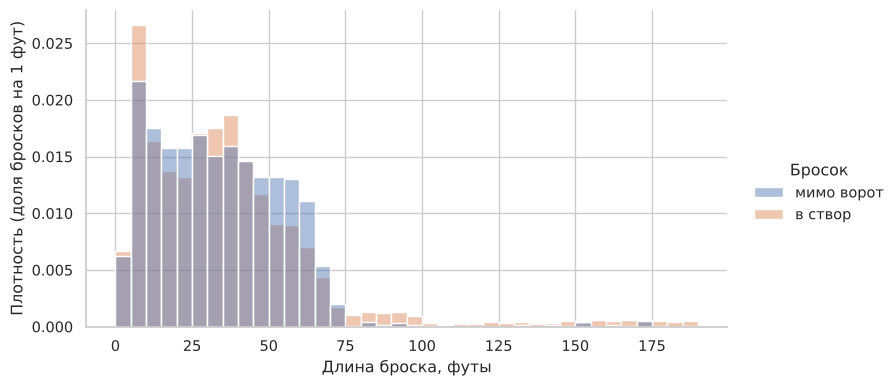

In [16]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'мимо ворот', 'в створ')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['мимо ворот', 'в створ'],
                stat='density', common_norm=False, binwidth=5, binrange=(0, 190),
                height=4, aspect=1.9, alpha=0.45)
g.set_axis_labels('Длина броска, футы', 'Плотность (доля бросков на 1 фут)')
g.legend.set_title('Бросок')
savefig('fig09_shot_length')
plt.show()

In [17]:
print(shots.groupby('Shot')['Shot Length'].describe())
ks = stats.ks_2samp(shots.loc[shots['Shot'] == 'в створ', 'Shot Length'],
                    shots.loc[shots['Shot'] == 'мимо ворот', 'Shot Length'])
print(f'Тест Колмогорова-Смирнова: D = {ks.statistic:.3f}, p-value = {ks.pvalue:.2g}')
near = shots[shots['Shot Length'] <= 89]
ks89 = stats.ks_2samp(near.loc[near['Shot'] == 'в створ', 'Shot Length'],
                      near.loc[near['Shot'] == 'мимо ворот', 'Shot Length'])
print(f'Только броски с чужой половины (до 89 футов): D = {ks89.statistic:.3f}, p-value = {ks89.pvalue:.2g}')
print(near.groupby('Shot')['Shot Length'].agg(['mean', 'median']))

# Доля бросков в створ по интервалам дистанции
bins = [0, 10, 20, 30, 40, 50, 60, 70, 89, 200]
shots['Distance'] = pd.cut(shots['Shot Length'], bins, include_lowest=True)
acc = shots.groupby('Distance', observed=True)['Shot'].agg(
    Shots='size', OnGoalShare=lambda s: (s == 'в створ').mean())
acc

             count    mean     std  min     25%     50%     75%      max
Shot                                                                    
в створ     4623.0  36.207  29.997  0.0  15.000  31.828  47.011  188.215
мимо ворот  2643.0  34.014  22.313  0.0  16.155  32.249  49.041  185.068
Тест Колмогорова-Смирнова: D = 0.051, p-value = 0.0003
Только броски с чужой половины (до 89 футов): D = 0.057, p-value = 4.5e-05
              mean  median
Shot                      
в створ     31.218  30.389
мимо ворот  32.791  31.890


,Shots,OnGoalShare
Distance,,
"(-0.001, 10.0]",1217,0.676
"(10.0, 20.0]",1079,0.608
"(20.0, 30.0]",1128,0.620
"(30.0, 40.0]",1237,0.671
"(40.0, 50.0]",977,0.624
"(50.0, 60.0]",759,0.542
"(60.0, 70.0]",473,0.552
"(70.0, 89.0]",145,0.772
"(89.0, 200.0]",251,0.880


Откуда хвост бросков со своей половины. Нужно знать, был ли в момент броска вратарь в воротах соперника.
Составы на льду в строке события записаны **после** события (у гола в строке уже стоит вратарь,
вышедший после смены, а у гола в пустые ворота стоит вернувшийся в ворота вратарь), поэтому
берём состав из предыдущей строки той же игры, то есть состояние перед событием.

In [18]:
prev_away_goalie = events.groupby('Game ID')["Away Team's Goalie"].shift()
prev_home_goalie = events.groupby('Game ID')["Home Team's Goalie"].shift()
# вратарь соперника перед событием (для событий команды хозяев это вратарь гостей)
events['Opp Goalie Before'] = np.where(is_home, prev_away_goalie, prev_home_goalie)
events['Empty Net'] = events['Opp Goalie Before'].isna() & events['Team Making the Play'].notna()

shots = shots.join(events[['Opp Goalie Before', 'Empty Net']])
far = shots[shots['Shot Length'] > 89]
print('Бросков дальше 89 футов (со своей половины):', len(far))
print(pd.crosstab(far['Play Type'], far['Empty Net'].map({True: 'пустые ворота', False: 'вратарь в воротах'}),
                  margins=True, margins_name='Всего'))
print(far.loc[far['Play Type'] == 'shot-on-goal', 'Play Zone'].value_counts())

Бросков дальше 89 футов (со своей половины): 251
Empty Net     вратарь в воротах  пустые ворота  Всего
Play Type                                            
goal                          3             16     19
missed-shot                   9             21     30
shot-on-goal                202              0    202
Всего                       214             37    251
Play Zone
Defensive    128
Neutral       74
Name: count, dtype: int64


Вывод: если смотреть на основную массу бросков (до 70 футов), распределения длины точных и неточных бросков
похожи, медианы почти совпадают (31,8 и 32,2 фута). Различия есть в деталях. Точные броски относительно чаще
наносятся с самого близкого расстояния (до 10 футов, добивания и броски от ворот) и с 30–40 футов, а неточные
с 45–70 футов, то есть с дальних позиций чаще промахиваются. Если отбросить броски со своей половины, точные
в среднем короче неточных примерно на 1,5 фута (медианы 30,4 и 31,9). Тест Колмогорова–Смирнова отвергает
совпадение распределений (p < 0,001), но расстояние между ними мало (D = 0,05–0,06).

Длинный хвост точных бросков со своей половины (больше 89 футов) объясняется так.
1. Это в основном выбросы шайбы из своей зоны и через всю площадку в сторону чужих ворот: из 202 таких бросков
   в створ 128 сделаны из своей зоны и 74 из средней. Если такой выброс летит в створ, вратарь его ловит или
   отбивает, и судьи-статистики записывают бросок по воротам. Если же он летит мимо, это обычный вброс
   в зону или проброс, бросок мимо ворот при этом обычно не регистрируется. Поэтому хвоста неточных бросков нет.
2. Вторая часть хвоста связана с пустыми воротами в концовках матчей: 16 из 19 голов со своей половины
   забиты в пустые ворота. Прицельный бросок через всю площадку в пустые ворота тоже оказывается «точным».

## Задача 10. Доля точных бросков у каждой команды в каждой игре

Незаблокированные броски: `shot-on-goal`, `goal`, `missed-shot`. Точные: `shot-on-goal` и `goal`.

In [19]:
unblocked = events[is_shot]
numshots = pd.crosstab([unblocked['Game ID'], unblocked['Team Making the Play']],
                       unblocked['Play Type'])
numshots['Share of Shots on Goal'] = ((numshots['shot-on-goal'] + numshots['goal'])
                                      / numshots[SHOT_TYPES].sum(axis=1))
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [20]:
share = numshots['Share of Shots on Goal']
print(share.describe())

# Связь с результатом: у кого доля точных бросков выше, тот чаще выигрывает?
sh = share.unstack()
winner = np.where(games['Home Score'] > games['Away Score'], games['Home Team'], games['Away Team'])
loser = np.where(games['Home Score'] > games['Away Score'], games['Away Team'], games['Home Team'])
w_share = np.array([sh.loc[g, t] for g, t in zip(games.index, winner)])
l_share = np.array([sh.loc[g, t] for g, t in zip(games.index, loser)])
print(f'\nСредняя доля у победителей: {w_share.mean():.3f}, у проигравших: {l_share.mean():.3f}')
print(f'Победитель точнее в {np.mean(w_share > l_share):.1%} матчей '
      f'({(w_share > l_share).sum()} из {len(games)}; ничьих по доле {(w_share == l_share).sum()})')
t = stats.ttest_rel(w_share, l_share)
print(f'Парный t-тест: t = {t.statistic:.2f}, p-value = {t.pvalue:.3f}')
gl = numshots['goal']
r = stats.pearsonr(share, gl)
print(f'Корреляция доли точных бросков с числом голов команды в матче: r = {r[0]:.3f}, p = {r[1]:.3g}')

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

Средняя доля у победителей: 0.632, у проигравших: 0.646
Победитель точнее в 45.1% матчей (37 из 82; ничьих по доле 0)
Парный t-тест: t = -1.04, p-value = 0.300
Корреляция доли точных бросков с числом голов команды в матче: r = 0.113, p = 0.15


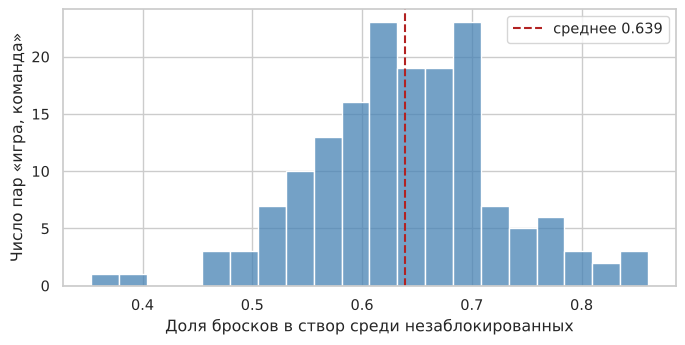

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(share, binwidth=0.025, color='steelblue', ax=ax)
ax.axvline(share.mean(), color='firebrick', ls='--', label=f'среднее {share.mean():.3f}')
ax.set_xlabel('Доля бросков в створ среди незаблокированных')
ax.set_ylabel('Число пар «игра, команда»')
ax.legend()
plt.tight_layout()
savefig('fig10_share_hist')
plt.show()

Вывод: в среднем в створ летит 64% незаблокированных бросков, в половине случаев доля лежит между 58% и 69%.
Разброс по отдельным матчам заметный, от 35% до 86%. При этом точность почти не связана с результатом.
У победителей средняя доля даже немного ниже (63,2% против 64,6%), победитель бросал точнее соперника лишь
в 37 матчах из 82, а парный t-тест разницы не находит (p = 0,30). Корреляция доли точных бросков с числом
забитых голов слабая и незначимая (r = 0,11). Для результата важнее, сколько бросков команда наносит и откуда
(см. задачи 13 и 22), а не то, какая их доля попала в створ.

## Задача 11. Команды с самой высокой и самой низкой средней долей точных бросков

In [22]:
avgnumshots = share.groupby(level='Team Making the Play').mean()
print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


In [23]:
# Число игр и общая доля (все броски команды вместе) для сравнения
team_tot = numshots.groupby(level='Team Making the Play')[SHOT_TYPES].sum()
team_tab = pd.DataFrame({
    'Games': share.groupby(level='Team Making the Play').size(),
    'Mean share': avgnumshots,
    'Pooled share': (team_tot['shot-on-goal'] + team_tot['goal']) / team_tot.sum(axis=1),
}).sort_values('Mean share', ascending=False)
print(team_tab)

# Есть ли значимые различия между командами? Хи-квадрат для таблицы «команда x (в створ, мимо)»
cont = np.c_[team_tot['shot-on-goal'] + team_tot['goal'], team_tot['missed-shot']]
chi2, p, dof, _ = stats.chi2_contingency(cont)
print(f'\nХи-квадрат = {chi2:.1f}, df = {dof}, p-value = {p:.2g}')
print(f'Корреляция средней доли с числом сыгранных игр: '
      f'r = {stats.pearsonr(team_tab["Games"], team_tab["Mean share"])[0]:.3f}')

                      Games  Mean share  Pooled share
Team Making the Play                                 
Edmonton Oilers           6       0.706         0.700
Philadelphia Flyers      10       0.684         0.681
Dallas Stars              6       0.670         0.669
Minnesota Wild           11       0.656         0.657
Colorado Avalanche       13       0.653         0.649
Anaheim Ducks            12       0.649         0.648
Montréal Canadiens       19       0.644         0.648
Los Angeles Kings         4       0.642         0.639
Boston Bruins             6       0.638         0.637
Ottawa Senators           4       0.635         0.618
Vegas Golden Knights     22       0.634         0.626
Buffalo Sabres           13       0.626         0.629
Tampa Bay Lightning       7       0.626         0.624
Carolina Hurricanes      19       0.615         0.613
Utah Mammoth              6       0.599         0.609
Pittsburgh Penguins       6       0.554         0.554

Хи-квадрат = 23.4, df = 15,

Вывод: самая высокая средняя доля точных бросков у Edmonton Oilers (70,6%), самая низкая у Pittsburgh Penguins (55,4%).
Обе команды сыграли всего по 6 матчей, как и Dallas (третье место) и Utah (второе с конца), и вылетели в первом раунде.
На малом числе игр средние особенно шумные, поэтому крайние места в рейтинге во многом достаются командам
с короткой серией. Проверка хи-квадрат на однородность долей между 16 командами даёт p = 0,077, то есть на 5%-м
уровне различия между командами незначимы. Обладатель Кубка Стэнли Carolina Hurricanes вообще в тройке
худших (61,5%), а корреляция средней доли с числом сыгранных матчей (то есть с тем, как далеко команда прошла)
равна −0,01. Точность бросков не выглядит устойчивым командным качеством, по крайней мере на такой выборке.

## Задача 12. Среднее число бросков в створ и голов за игру

Броски в створ по определению НХЛ включают голы, поэтому `Shot` считается по событиям
`shot-on-goal` и `goal`. Среднее берётся по всем играм команды: пары «игра, команда»,
в которых команда не забила, добавляем с нулём через `reindex`.

In [24]:
team_games = pd.MultiIndex.from_arrays(
    [np.r_[games.index, games.index], np.r_[games['Away Team'], games['Home Team']]],
    names=['Game ID', 'Team Making the Play'])

def per_team_game(types):
    ev = events[events['Play Type'].isin(types)]
    return ev.groupby(['Game ID', 'Team Making the Play']).size().reindex(team_games, fill_value=0)

team_game_stats = pd.DataFrame({
    'Shot': per_team_game(['shot-on-goal', 'goal']),
    'Goal': per_team_game(['goal']),
})
avgshots = team_game_stats.groupby(level='Team Making the Play').mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## Задача 13. Связь бросков в створ и голов

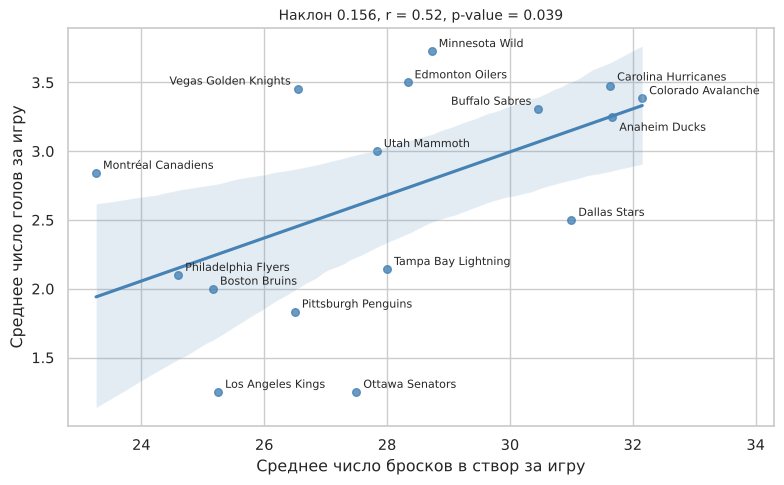

По командам (n = 16): наклон = 0.156, r = 0.521, R2 = 0.271, p-value = 0.039


In [25]:
lr = stats.linregress(avgshots['Shot'], avgshots['Goal'])

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=avgshots, x='Shot', y='Goal', ax=ax, color='steelblue',
            scatter_kws={'s': 30}, seed=0)
# подписи; у плотной группы справа вверху смещаем их, чтобы не налезали
label_pos = {'Vegas Golden Knights': (-5, 3, 'right'), 'Carolina Hurricanes': (5, 4, 'left'),
             'Buffalo Sabres': (-5, 3, 'right'), 'Anaheim Ducks': (5, -10, 'left')}
for team, row in avgshots.iterrows():
    dx, dy, ha = label_pos.get(team, (5, 3, 'left'))
    ax.annotate(team, (row['Shot'], row['Goal']), xytext=(dx, dy), textcoords='offset points',
                ha=ha, fontsize=8)
ax.set_xlim(22.8, 34.3)
ax.set_xlabel('Среднее число бросков в створ за игру')
ax.set_ylabel('Среднее число голов за игру')
ax.set_title(f'Наклон {lr.slope:.3f}, r = {lr.rvalue:.2f}, p-value = {lr.pvalue:.3f}', fontsize=10)
plt.tight_layout()
savefig('fig13_shots_goals')
plt.show()

print(f'По командам (n = 16): наклон = {lr.slope:.3f}, r = {lr.rvalue:.3f}, '
      f'R2 = {lr.rvalue**2:.3f}, p-value = {lr.pvalue:.3f}')

In [26]:
# Для сравнения: та же связь на уровне отдельных матчей (164 наблюдения)
lr_g = stats.linregress(team_game_stats['Shot'], team_game_stats['Goal'])
print(f'По матчам (n = {len(team_game_stats)}): наклон = {lr_g.slope:.3f}, '
      f'r = {lr_g.rvalue:.3f}, p-value = {lr_g.pvalue:.3f}')
# Реализация бросков: доля голов среди бросков в створ
conv = team_game_stats.groupby(level=1).sum()
conv['Shooting %'] = conv['Goal'] / conv['Shot']
print(conv.sort_values('Shooting %', ascending=False)['Shooting %'].round(3).to_string())

По матчам (n = 164): наклон = 0.046, r = 0.196, p-value = 0.012
Team Making the Play
Vegas Golden Knights    0.130
Minnesota Wild          0.130
Edmonton Oilers         0.124
Montréal Canadiens      0.122
Carolina Hurricanes     0.110
Buffalo Sabres          0.109
Utah Mammoth            0.108
Colorado Avalanche      0.105
Anaheim Ducks           0.103
Philadelphia Flyers     0.085
Dallas Stars            0.081
Boston Bruins           0.079
Tampa Bay Lightning     0.077
Pittsburgh Penguins     0.069
Los Angeles Kings       0.050
Ottawa Senators         0.045


Вывод: связь видна, но она умеренная. Коэффициент корреляции по 16 командам 0,52 (R² = 0,27), наклон 0,156:
лишний бросок в створ за игру в среднем даёт около 0,16 гола за игру. Связь значима на 5%-м уровне
(p = 0,039), хотя наблюдений всего 16. Сильно от линии отклоняются команды с необычной реализацией.
Montréal и Vegas забивали много при малом числе бросков (реализация 12–13% бросков в створ), Ottawa и Los Angeles,
наоборот, при средних бросках забивали по 1,25 гола (реализация 4,5–5%). На уровне отдельных матчей
(164 наблюдения) связь ещё слабее: r = 0,20, хотя тоже значима (p = 0,012). Число бросков объясняет лишь
малую часть различий в голах, остальное приходится на качество моментов, игру вратарей и случайность.

## Задача 14. Матч с наибольшим числом ударов по воротам

In [27]:
ATTEMPT_TYPES = ['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot']
attempts = events[events['Play Type'].isin(ATTEMPT_TYPES)].groupby('Game ID').size()
idxmax = attempts.idxmax()
print(gameInfo(idxmax))
print('Ударов:', attempts.max())
print(attempts.nlargest(5).to_frame('Attempts').assign(Info=lambda d: d.index.map(gameInfo)))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Ударов: 208
            Attempts                                                                       Info
Game ID                                                                                        
2025030132       208       Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
2025030164       169                Minnesota Wild - Dallas Stars (3 - 2, Final/OT, 2026-04-25)
2025030413       163  Vegas Golden Knights - Carolina Hurricanes (5 - 4, Final/2OT, 2026-06-06)
2025030126       156     Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
2025030175       154         Vegas Golden Knights - Utah Mammoth (5 - 4, Final/2OT, 2026-04-29)


Вывод: больше всего ударов (208) было в матче первого раунда Carolina Hurricanes – Ottawa Senators (3:2, победа
во втором овертайме). Во многом это следствие длительности: матч шёл почти пять периодов (последний гол на 13:53
пятого периода), следующий по числу ударов матч набрал 169.

## Задача 15. Карта ударов в этом матче

У события `blocked-shot` в поле `Team Making the Play` записана команда, чей бросок заблокировали
(бросающий игрок в `Player in the Event #2` всегда из этой команды), координаты относятся к месту блока.

Чтобы гости всегда атаковали левые ворота, а хозяева правые, отражаем координаты $(x,y)\mapsto(-x,-y)$
в тех периодах, где хозяева защищают правые ворота. В этом матче это нечётные периоды (1, 3, 5),
что совпадает с подсказкой в условии, но правило через `Home Team's Defending Side` работает для любого матча.

В примере кода из условия стоит `plt.axis('even')`, такого режима в matplotlib нет, используем `'equal'`.

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str


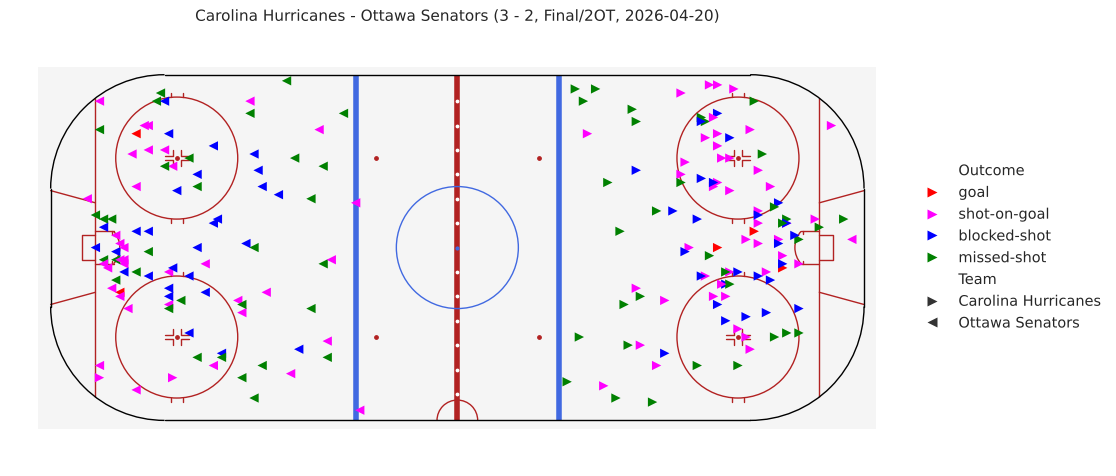

In [28]:
att = events[(events['Game ID'] == idxmax) & events['Play Type'].isin(ATTEMPT_TYPES)].copy()
print(att.groupby('Period')["Home Team's Defending Side"].first())

flip = att["Home Team's Defending Side"] == 'right'
att['x'] = np.where(flip, -att['X Coordinate on the Ice Rink'], att['X Coordinate on the Ice Rink'])
att['y'] = np.where(flip, -att['Y Coordinate on the Ice Rink'], att['Y Coordinate on the Ice Rink'])
home_team, away_team = games.loc[idxmax, ['Home Team', 'Away Team']]
att = att.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(11, 4.6))
plot_rink(False)
sns.scatterplot(data=att, x='x', y='y', hue='Outcome', style='Team',
                hue_order=ATTEMPT_TYPES, style_order=[home_team, away_team],
                palette=['red', 'magenta', 'blue', 'green'], markers=['>', '<'],
                s=45, edgecolor='none')
plt.axis('equal')
plt.axis('off')
sns.move_legend(plt.gca(), 'center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.title(gameInfo(idxmax), fontsize=11)
plt.tight_layout(pad=0.1)
savefig('fig15_shot_map')
plt.show()

In [29]:
# Проверка ориентации: у хозяев удары справа (x > 0), у гостей слева
print(pd.crosstab([att['Team'], att['Outcome']], np.where(att['x'] > 0, 'правая половина', 'левая половина')))

col_0                             левая половина  правая половина
Team                Outcome                                      
Carolina Hurricanes blocked-shot               0               26
                    goal                       0                3
                    missed-shot                0               34
                    shot-on-goal               2               44
Ottawa Senators     blocked-shot              28                0
                    goal                       2                0
                    missed-shot               32                0
                    shot-on-goal              36                1


Вывод: на карте видно, что удары сосредоточены в «слоте» перед воротами и в кругах вбрасывания, а заблокированные
броски в основном наносятся от синей линии и с кругов. Все пять голов забиты не дальше 27 футов от ворот,
победную шайбу во втором овертайме Jordan Martinook забросил с 25 футов. Carolina нанесла 109 ударов, Ottawa 99.
Несколько бросков в створ сделаны со своей половины, это те самые выбросы из задачи 9.

## Справочная таблица игроков (для задач 16–21)

Команду и число сыгранных матчей (GP) определяем по составам на льду: игрок считается сыгравшим
в матче, если хотя бы раз был на льду. По этим же данным выделяем вратарей.

In [30]:
players = on_ice.groupby('Player').agg(Team=('Team', 'first'), GP=('Game ID', 'nunique'))
players['Goalie'] = players.index.isin(goalie_names)
print(players.shape, '| вратарей:', players['Goalie'].sum())

def top10(series, name, extra=None):
    """Топ-10 с учётом ничьих на 10-м месте; добавляет команду и число игр."""
    s = series.nlargest(10, keep='all').rename(name)
    # при равных значениях упорядочиваем по фамилии, чтобы порядок не зависел от версии pandas
    s = s.sort_index().sort_values(ascending=False, kind='stable')
    out = players.reindex(s.index)[['Team', 'GP']].join(s)
    if extra is not None:
        out = out.join(extra)
    out.index.name = 'Player'
    return out

(372, 3) | вратарей: 25


## Задача 16. Лучшие снайперы

In [31]:
goal_ev = events[events['Play Type'] == 'goal'].copy()
goals_by_player = goal_ev['Player in the Event #1'].value_counts()
top10(goals_by_player, 'Goals')

,Team,GP,Goals
Player,,,
Brett Howden,Vegas Golden Knights,22,14
Pavel Dorofeyev,Vegas Golden Knights,22,12
Logan Stankoven,Carolina Hurricanes,19,11
Mitch Marner,Vegas Golden Knights,22,10
Jordan Staal,Carolina Hurricanes,19,8
Nikolaj Ehlers,Carolina Hurricanes,18,8
Alex Newhook,Montréal Canadiens,19,7
Jackson Blake,Carolina Hurricanes,19,7
Mark Stone,Vegas Golden Knights,17,7


Вывод: лучший снайпер плей-офф Brett Howden (Vegas, 14 голов), за ним Pavel Dorofeyev (12) и Logan Stankoven (11).
На 10-м месте ничья: семь голов у шести игроков, поэтому в списке 12 фамилий. В таблице преобладают игроки
финалистов Vegas и Carolina, которые сыграли больше всех матчей (22 и 19).

## Задача 17. Лучшие ассистенты

In [32]:
assists_by_player = pd.concat([goal_ev['Player in the Event #2'],
                               goal_ev['Player in the Event #3']]).dropna().value_counts()
top10(assists_by_player, 'Assists')

,Team,GP,Assists
Player,,,
Jack Eichel,Vegas Golden Knights,22,20
Mitch Marner,Vegas Golden Knights,22,19
Jackson Blake,Carolina Hurricanes,19,13
Lane Hutson,Montréal Canadiens,19,13
Martin Necas,Colorado Avalanche,13,12
Nick Suzuki,Montréal Canadiens,19,12
Shea Theodore,Vegas Golden Knights,22,12
Taylor Hall,Carolina Hurricanes,19,12
Kirill Kaprizov,Minnesota Wild,11,11


Вывод: больше всех передач у Jack Eichel (20) и Mitch Marner (19) из Vegas. В десятке три защитника
(Lane Hutson, Shea Theodore, Quinn Hughes): у защитников голевые передачи обычно и составляют основную часть очков.

## Задача 18. Лучшие бомбардиры (гол + пас)

In [33]:
points = pd.DataFrame({'Goals': goals_by_player, 'Assists': assists_by_player}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
top10(points['Points'], 'Points', extra=points[['Goals', 'Assists']])

,Team,GP,Points,Goals,Assists
Player,,,,,
Mitch Marner,Vegas Golden Knights,22,29,10,19
Jack Eichel,Vegas Golden Knights,22,22,2,20
Jackson Blake,Carolina Hurricanes,19,20,7,13
Taylor Hall,Carolina Hurricanes,19,19,7,12
Brett Howden,Vegas Golden Knights,22,18,14,4
Nikolaj Ehlers,Carolina Hurricanes,18,18,8,10
Shea Theodore,Vegas Golden Knights,22,18,6,12
Lane Hutson,Montréal Canadiens,19,16,3,13
Logan Stankoven,Carolina Hurricanes,19,16,11,5


Вывод: лучший бомбардир Mitch Marner, 29 очков (10 + 19). Из-за ничьей на 10-м месте (по 16 очков) в списке 11 игроков.

## Задача 19. Больше всего бросков в створ за игру

Бросок в створ: `shot-on-goal` или `goal`, бросающий в `Player in the Event #1`.
Делим на число матчей, в которых игрок выходил на лёд (а не на число матчей, где он бросал,
иначе матчи без бросков выпали бы из знаменателя).

In [34]:
sog_ev = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
sog_by_player = sog_ev['Player in the Event #1'].value_counts()
sog_per_game = (sog_by_player / players['GP']).dropna()
top10(sog_per_game, 'SOG per game', extra=sog_by_player.rename('SOG'))

,Team,GP,SOG per game,SOG
Player,,,,
Jason Robertson,Dallas Stars,6,5.000,30
Dylan Guenther,Utah Mammoth,6,4.500,27
Nikita Kucherov,Tampa Bay Lightning,7,4.429,31
Matt Boldy,Minnesota Wild,11,4.364,48
Quinton Byfield,Los Angeles Kings,4,4.250,17
Darren Raddysh,Tampa Bay Lightning,7,4.000,28
Joel Eriksson Ek,Minnesota Wild,6,4.000,24
Alex Laferriere,Los Angeles Kings,4,3.750,15
David Pastrnak,Boston Bruins,6,3.667,22


In [35]:
# Устойчивость: тот же список среди игроков, сыгравших не меньше 10 матчей
top10(sog_per_game[players['GP'].reindex(sog_per_game.index) >= 10], 'SOG per game',
      extra=sog_by_player.rename('SOG'))

,Team,GP,SOG per game,SOG
Player,,,,
Matt Boldy,Minnesota Wild,11,4.364,48
Nathan MacKinnon,Colorado Avalanche,13,3.615,47
Alex Tuch,Buffalo Sabres,13,3.538,46
Rasmus Dahlin,Buffalo Sabres,13,3.538,46
Tage Thompson,Buffalo Sabres,13,3.538,46
Leo Carlsson,Anaheim Ducks,12,3.417,41
Cutter Gauthier,Anaheim Ducks,12,3.250,39
Ryan Hartman,Minnesota Wild,11,3.182,35
Logan Stankoven,Carolina Hurricanes,19,2.895,55


Вывод: по формальному критерию первое место у Jason Robertson (Dallas, 5 бросков в створ за игру за 6 матчей).
Верх списка заняли игроки, чьи команды рано вылетели: на коротком отрезке среднее выше и неустойчивее.
Если оставить игроков, сыгравших хотя бы 10 матчей, лидирует Matt Boldy (Minnesota, 4,36 за игру),
дальше Nathan MacKinnon (3,62) и тройка Buffalo с одинаковыми 46 бросками за 13 матчей.

## Задача 20. Больше всего силовых приёмов за игру

In [36]:
hits_by_player = events.loc[events['Play Type'] == 'hit', 'Player in the Event #1'].value_counts()
hits_per_game = (hits_by_player / players['GP']).dropna()
top10(hits_per_game, 'Hits per game', extra=hits_by_player.rename('Hits'))

,Team,GP,Hits per game,Hits
Player,,,,
Lawson Crouse,Utah Mammoth,6,6.333,38
Alex Turcotte,Los Angeles Kings,1,6.000,6
Alexander Petrovic,Dallas Stars,1,6.000,6
Yakov Trenin,Minnesota Wild,9,5.667,51
Dylan Cozens,Ottawa Senators,4,5.500,22
Vasily Podkolzin,Edmonton Oilers,6,5.333,32
Carl Grundstrom,Philadelphia Flyers,3,5.000,15
Ivan Barbashev,Vegas Golden Knights,22,5.000,110
Marcus Foligno,Minnesota Wild,11,5.000,55


In [37]:
top10(hits_per_game[players['GP'].reindex(hits_per_game.index) >= 10], 'Hits per game',
      extra=hits_by_player.rename('Hits'))

,Team,GP,Hits per game,Hits
Player,,,,
Ivan Barbashev,Vegas Golden Knights,22,5.000,110
Marcus Foligno,Minnesota Wild,11,5.000,55
William Carrier,Carolina Hurricanes,19,4.789,91
Cole Smith,Vegas Golden Knights,22,4.545,100
Jordan Staal,Carolina Hurricanes,19,4.526,86
Jeffrey Truchon-Viel,Anaheim Ducks,12,4.250,51
Travis Konecny,Philadelphia Flyers,10,4.100,41
Tim Washe,Anaheim Ducks,12,4.000,48
Keegan Kolesar,Vegas Golden Knights,21,3.905,82


Вывод: формально первый Lawson Crouse (Utah, 6,33 силового приёма за игру). На втором месте игроки, сыгравшие
всего один матч (Alex Turcotte и Alexander Petrovic, по 6 приёмов), это пример того, как малая выборка поднимает
среднее. Среди игроков с 10 и более матчами лидируют Ivan Barbashev (Vegas, 110 приёмов за 22 матча) и
Marcus Foligno (Minnesota), по 5 приёмов за игру.

## Задача 21. Вратари, хотя бы раз не пропустившие ни одного гола

Шаги:
1. Для каждого матча находим всех вратарей, которые хотя бы раз были в воротах (столбцы `Goalie`).
2. Гол засчитываем вратарю, который стоял в воротах **перед** голом (столбец `Opp Goalie Before` из задачи 9).
   Строка самого гола содержит состав после гола, и это даёт ошибки: при замене вратаря после гола
   гол «достаётся» сменщику, в голах в пустые ворота стоит вернувшийся вратарь, а у победных голов
   в овертайме вратаря нет вовсе.
3. Голы в пустые ворота (вратаря перед голом не было) ни на кого не записываем, как и в официальной статистике.
4. Отбираем вратарей, у которых хотя бы в одном матче 0 пропущенных.

In [38]:
goalie_games = pd.concat([
    events[['Game ID', 'Away Team', "Away Team's Goalie"]].set_axis(['Game ID', 'Team', 'Goalie'], axis=1),
    events[['Game ID', 'Home Team', "Home Team's Goalie"]].set_axis(['Game ID', 'Team', 'Goalie'], axis=1),
]).dropna().drop_duplicates()

ga = goal_ev.groupby(['Game ID', 'Opp Goalie Before']).size().rename('GA')
ga.index.names = ['Game ID', 'Goalie']
goalie_games = goalie_games.join(ga, on=['Game ID', 'Goalie']).fillna({'GA': 0})
goalie_games['GA'] = goalie_games['GA'].astype(int)
# Отыграл ли вратарь весь матч (был единственным вратарём своей команды в этой игре)
goalie_games['Full game'] = goalie_games.groupby(['Game ID', 'Team'])['Goalie'].transform('size') == 1

print('Голов в пустые ворота:', goal_ev['Empty Net'].sum(),
      '| голов, записанных на вратарей:', goalie_games['GA'].sum(), '| всего голов:', len(goal_ev))

# Проверка правдоподобия: голы в пустые ворота должны забиваться в конце 3-го периода ведущей командой
en = goal_ev[goal_ev['Empty Net']]
scorer_home = en['Team Making the Play'] == en['Home Team']
lead_before = np.where(scorer_home, en['Cumulated Home Score'] - 1 - en['Cumulated Away Score'],
                       en['Cumulated Away Score'] - 1 - en['Cumulated Home Score'])
print('Периоды:', en['Period'].unique(), '| максимум оставшегося времени:', en['Remaining Time'].max(),
      '| перед голом в пустые ворота забившие вели всегда:', (lead_before > 0).all())

zero = goalie_games[goalie_games['GA'] == 0].copy()
zero['Game'] = zero['Game ID'].map(gameInfo)
zero = zero.sort_values(['Goalie', 'Game ID']).reset_index(drop=True)
print(zero[['Goalie', 'Team', 'Full game', 'Game']].to_string(max_colwidth=80))

Голов в пустые ворота: 34 | голов, записанных на вратарей: 452 | всего голов: 486
Периоды: [3] | максимум оставшегося времени: 05:48 | перед голом в пустые ворота забившие вели всегда: True
                  Goalie                 Team  Full game                                                                     Game
0              Alex Lyon       Buffalo Sabres      False                Buffalo Sabres - Boston Bruins (2 - 4, Final, 2026-04-21)
1     Andrei Vasilevskiy  Tampa Bay Lightning       True   Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
2          Brandon Bussi  Carolina Hurricanes       True    Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)
3             Dan Vladar  Philadelphia Flyers       True     Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
4             Dan Vladar  Philadelphia Flyers       True  Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
5      Frederik Andersen  Caro

In [39]:
shutout_goalies = sorted(zero['Goalie'].unique())
print(len(shutout_goalies), 'вратарей:', shutout_goalies)

8 вратарей: ['Alex Lyon', 'Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood', 'Ukko-Pekka Luukkonen']


In [40]:
# Для сравнения: что получилось бы, если брать вратаря прямо из строки гола
naive_goalie = np.where(goal_ev['Team Making the Play'] == goal_ev['Home Team'],
                        goal_ev["Away Team's Goalie"], goal_ev["Home Team's Goalie"])
naive_ga = goal_ev.assign(Goalie=naive_goalie).groupby(['Game ID', 'Goalie']).size().rename('GA naive')
naive = goalie_games[['Game ID', 'Goalie']].join(naive_ga, on=['Game ID', 'Goalie']).fillna({'GA naive': 0})
naive_list = sorted(naive.loc[naive['GA naive'] == 0, 'Goalie'].unique())
print('Наивный подход:', naive_list)
print('Расхождение со строгим подходом:', sorted(set(naive_list) ^ set(shutout_goalies)))

Наивный подход: ['Andrei Vasilevskiy', 'Arturs Silovs', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Jakub Dobes', 'Joonas Korpisalo', 'Scott Wedgewood']
Расхождение со строгим подходом: ['Alex Lyon', 'Arturs Silovs', 'Jakub Dobes', 'Ukko-Pekka Luukkonen']


Вывод: хотя бы в одном матче не пропустили ни одного гола восемь вратарей. Полные «сухие» матчи у Frederik Andersen
(три раза), Dan Vladar (дважды), Andrei Vasilevskiy и Brandon Bussi (шестой, решающий матч финала).
Ещё четверо не пропускали, выходя на замену: Alex Lyon, Ukko-Pekka Luukkonen (оба Buffalo), Joonas Korpisalo
и Scott Wedgewood.

Сравнение с наивным подходом показывает, зачем нужен состав перед голом. Если брать вратаря из строки гола,
в список попали бы Arturs Silovs и Jakub Dobes: пропущенные ими победные голы в овертайме ни на кого бы не записались,
потому что после финального гола в строке вратаря нет. А Lyon и Luukkonen выпали бы, потому что им достались бы
голы, после которых их выпустили на замену.

## Задача 22. Собственный вопрос: насколько вероятен гол с данной точки и кто забивает больше «ожидаемого»

Вопрос: как вероятность гола зависит от дистанции и угла броска, и какие команды в плей-офф реализовали
моменты лучше или хуже, чем можно ожидать по качеству их бросков (модель ожидаемых голов, xG)?

Данные: незаблокированные броски (`shot-on-goal`, `goal`, `missed-shot`), когда в воротах соперника был вратарь.
Броски в пустые ворота исключаем, это другая игровая ситуация.
Угол считаем от продольной оси площадки: 0° соответствует броску прямо по центру,
больше 90° соответствует броску из-за линии ворот.
Модель: логистическая регрессия $P(\text{гол}) = \Lambda(\beta_0 + \beta_1 \cdot \text{дистанция} + \beta_2 \cdot \text{угол})$.

In [41]:
xg = events[is_shot & ~events['Empty Net']].copy()
xg['Goal'] = (xg['Play Type'] == 'goal').astype(int)
# координаты в системе, где атакуемые ворота справа в точке (89, 0)
xg['xa'] = xg['X Coordinate on the Ice Rink'] * attack_dir[xg.index]
xg['ya'] = xg['Y Coordinate on the Ice Rink'] * attack_dir[xg.index]
xg['Angle'] = np.degrees(np.arctan2(xg['ya'].abs(), 89 - xg['xa']))
print(len(xg), 'бросков,', xg['Goal'].sum(), 'голов, реализация', round(xg['Goal'].mean(), 4))

7197 бросков, 452 голов, реализация 0.0628


In [42]:
X1 = sm.add_constant(xg[['Shot Length']])
X2 = sm.add_constant(xg[['Shot Length', 'Angle']])
m1 = sm.Logit(xg['Goal'], X1).fit(disp=0)
m2 = sm.Logit(xg['Goal'], X2).fit(disp=0)
print(m2.summary2().tables[1].round(4))
from sklearn.metrics import roc_auc_score
print(f'\nAUC: только дистанция {roc_auc_score(xg["Goal"], m1.predict(X1)):.3f}, '
      f'дистанция + угол {roc_auc_score(xg["Goal"], m2.predict(X2)):.3f}')
print(f'Псевдо-R2 Макфаддена: {m1.prsquared:.3f} и {m2.prsquared:.3f}')
lr_stat = 2 * (m2.llf - m1.llf)
print(f'LR-тест на значимость угла: {lr_stat:.2f}, p-value = {stats.chi2.sf(lr_stat, 1):.3g}')
xg['xG'] = m2.predict(X2)
# Предельный эффект: насколько падает вероятность гола при удалении на 10 футов
for d in [10, 20, 30, 40, 60]:
    p = m2.predict(pd.DataFrame({'const': [1.0], 'Shot Length': [d], 'Angle': [20.0]})).iloc[0]
    print(f'P(гол | {d} футов, угол 20°) = {p:.3f}')

             Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
const       -1.121     0.111 -10.084    0.0  -1.339  -0.903
Shot Length -0.039     0.003 -12.780    0.0  -0.045  -0.033
Angle       -0.016     0.002  -7.183    0.0  -0.020  -0.011

AUC: только дистанция 0.688, дистанция + угол 0.717
Псевдо-R2 Макфаддена: 0.053 и 0.070
LR-тест на значимость угла: 55.98, p-value = 7.31e-14
P(гол | 10 футов, угол 20°) = 0.138
P(гол | 20 футов, угол 20°) = 0.098
P(гол | 30 футов, угол 20°) = 0.068
P(гол | 40 футов, угол 20°) = 0.047
P(гол | 60 футов, угол 20°) = 0.022


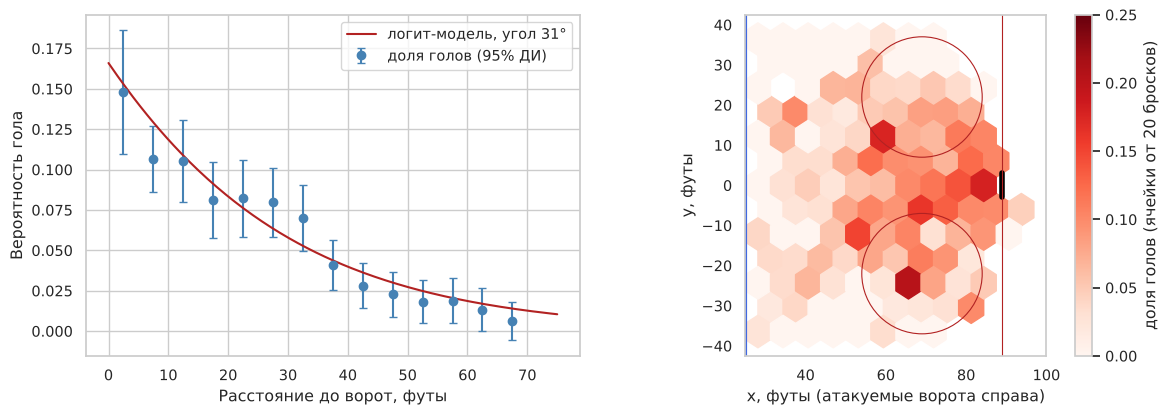

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1, 1.15]})

# слева: доля голов по дистанции и кривая модели (при медианном угле)
b = pd.cut(xg['Shot Length'], np.arange(0, 75, 5))
emp = xg.groupby(b, observed=True).agg(rate=('Goal', 'mean'), n=('Goal', 'size'))
mid = [iv.mid for iv in emp.index]
se = np.sqrt(emp['rate'] * (1 - emp['rate']) / emp['n'])
ax = axes[0]
ax.errorbar(mid, emp['rate'], yerr=1.96 * se, fmt='o', color='steelblue', capsize=3,
            label='доля голов (95% ДИ)')
dgrid = np.linspace(0, 75, 200)
med_angle = xg['Angle'].median()
ax.plot(dgrid, m2.predict(np.c_[np.ones_like(dgrid), dgrid, np.full_like(dgrid, med_angle)]),
        color='firebrick', label=f'логит-модель, угол {med_angle:.0f}°')
ax.set_xlabel('Расстояние до ворот, футы')
ax.set_ylabel('Вероятность гола')
ax.legend()

# справа: реализация бросков по зонам атакующей половины
ax = axes[1]
hb = ax.hexbin(xg['xa'], xg['ya'], C=xg['Goal'], reduce_C_function=np.mean, gridsize=(12, 7),
               extent=(25, 100, -42.5, 42.5), mincnt=20, cmap='Reds', vmin=0, vmax=0.25)
ax.plot([89, 89], [-3, 3], color='black', lw=4)
ax.add_patch(plt.Circle((69, 22), 15, fill=False, color='firebrick', lw=0.8))
ax.add_patch(plt.Circle((69, -22), 15, fill=False, color='firebrick', lw=0.8))
ax.axvline(25, color='royalblue', lw=3)
ax.axvline(89, color='firebrick', lw=0.8)
ax.set_xlim(25, 100); ax.set_ylim(-42.5, 42.5); ax.set_aspect('equal')
ax.set_xlabel('x, футы (атакуемые ворота справа)'); ax.set_ylabel('y, футы')
fig.colorbar(hb, ax=ax, label='доля голов (ячейки от 20 бросков)')
ax.grid(False)
plt.tight_layout()
savefig('fig22_xg')
plt.show()

In [44]:
# Сравнение фактических голов с ожидаемыми: в атаке (реализация) и в обороне (игра вратарей)
xg['Defending Team'] = np.where(xg['Team Making the Play'] == xg['Home Team'],
                                xg['Away Team'], xg['Home Team'])
off = xg.groupby('Team Making the Play').agg(Goals=('Goal', 'sum'), xG=('xG', 'sum'))
dfn = xg.groupby('Defending Team').agg(GA=('Goal', 'sum'), xGA=('xG', 'sum'))
team_xg = off.join(dfn)
team_xg['Games'] = team_game_stats.groupby(level=1).size()
team_xg['Finishing +/-'] = team_xg['Goals'] - team_xg['xG']
team_xg['Goaltending +/-'] = team_xg['xGA'] - team_xg['GA']
team_xg['xG diff / game'] = (team_xg['xG'] - team_xg['xGA']) / team_xg['Games']
team_xg.index.name = 'Team'
team_xg = team_xg.sort_values('Games', ascending=False)
team_xg.round(2)

,Goals,xG,GA,xGA,Games,Finishing +/-,Goaltending +/-,xG diff / game
Team,,,,,,,,
Vegas Golden Knights,70,61.72,59,59.07,22,8.28,0.07,0.12
Carolina Hurricanes,60,60.45,38,46.19,19,-0.45,8.19,0.75
Montréal Canadiens,52,45.45,53,58.13,19,6.55,5.13,-0.67
Buffalo Sabres,40,40.62,38,34.67,13,-0.62,-3.33,0.46
Colorado Avalanche,38,39.55,33,33.96,13,-1.55,0.96,0.43
Anaheim Ducks,36,33.48,40,30.99,12,2.52,-9.01,0.21
Minnesota Wild,36,29.01,34,34.66,11,6.99,0.66,-0.51
Philadelphia Flyers,20,22.46,23,29.82,10,-2.46,6.82,-0.74
Tampa Bay Lightning,15,19.25,16,15.89,7,-4.25,-0.11,0.48


In [45]:
# Вратари: пропущено против ожидаемого (только броски, когда вратарь был в воротах)
gk = xg.groupby('Opp Goalie Before').agg(Shots=('Goal', 'size'), GA=('Goal', 'sum'), xGA=('xG', 'sum'))
gk['Saved above expected'] = gk['xGA'] - gk['GA']
gk = gk[gk['Shots'] >= 150].sort_values('Saved above expected', ascending=False)
gk.index.name = 'Goalie'
gk.round(2)

,Shots,GA,xGA,Saved above expected
Goalie,,,,
Dan Vladar,489,23,29.82,6.82
Jakub Dobes,901,52,58.05,6.05
Linus Ullmark,226,9,13.93,4.93
Brandon Bussi,150,6,10.45,4.45
Frederik Andersen,544,32,35.73,3.73
Jesper Wallstedt,506,30,32.38,2.38
Jeremy Swayman,288,18,18.58,0.58
Anton Forsberg,192,11,11.39,0.39
Carter Hart,1018,59,59.07,0.07


Вывод по задаче 22.

1. Вероятность гола быстро падает с расстоянием: при угле 20° с 10 футов забивается примерно 14% бросков,
   с 30 футов 7%, с 60 футов около 2%. Каждый лишний фут снижает логарифм шансов на 0,039, каждый градус угла
   на 0,016; оба эффекта значимы, а угол заметно улучшает модель (LR-тест, p < 0,001; AUC растёт с 0,69 до 0,72).
   Карта справа показывает то же: опасная зона это «слот» между кругами вбрасывания на 5–30 футов от ворот.
2. Модель объясняет лишь малую часть исходов (псевдо-R² 0,07): по координатам не видно добивания, броска
   после передачи через площадку, игры в большинстве, помех вратарю. Поэтому оценки ниже нужно читать как грубые.
3. Чемпион Carolina Hurricanes по качеству моментов был лучшей командой турнира (+0,75 ожидаемого гола за игру
   в свою пользу) и вдобавок пропустил на 8 голов меньше ожидаемого; в атаке забил ровно столько, сколько «положено».
   Финалист Vegas, наоборот, почти не выигрывал по качеству моментов (+0,12 за игру), но реализовал на 8 голов больше
   ожидаемого. Montréal дошёл до финала конференции, уступая соперникам по xG (−0,67 за игру), благодаря реализации (+6,6)
   и вратарю Jakub Dobes, который пропустил на 6 голов меньше ожидаемого.
4. Среди вратарей с 150+ бросками лучше всего ожидания превзошли Dan Vladar и Jakub Dobes, хуже всего сыграл Lukas Dostal
   (Anaheim, на 9,6 гола больше ожидаемого), что во многом объясняет отрицательный баланс Anaheim в обороне.